# Supplemental Figure 2, Panel K

Barplot of top 15 BAFdep features (based on ridge regression coefficient) in HepG2 and H1 ESCs

*Output: PanelK.pdf*

# Setup

In [1]:
library(tidyverse)
library(patchwork)
library(here)
here::i_am("figures/SuppFig2/PanelK/PanelK.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank()))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig2/PanelK

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



# Load data

In [2]:
# read in feature importance metrics
#HepG2
hepg2 <- read.delim(
  here(
    "inputs", "ReModEx", "HepG2", "enh_only",
    "feature_importance.csv"
  ),
  sep = ","
) %>%
  rename("gene_name" = "feature")

#H1 ESC
h1 <- read.delim(
  here(
    "inputs", "ReModEx", "H1", "enh_only", "ACBI1",
    "feature_importance.csv"
  ),
  sep = ","
) %>%
  rename("gene_name" = "feature")


# Generate plots

In [3]:
p1 <- hepg2 %>% arrange(Ridge_coef) %>% head(15) %>% 
        ggplot(aes(y=reorder(gene_name, -Ridge_coef), x=-Ridge_coef)) + geom_col() + ggtitle("HepG2") + scale_x_continuous(limits=c(0,0.3), breaks=c(0,0.15,0.3))
p2 <- h1 %>% arrange(Ridge_coef) %>% head(15) %>% 
        ggplot(aes(y=reorder(gene_name, -Ridge_coef), x=-Ridge_coef)) + geom_col() + ggtitle("H1 ESC") + scale_x_continuous(limits=c(0,0.1), breaks=c(0,0.05,0.1))


# Assemble figure panel

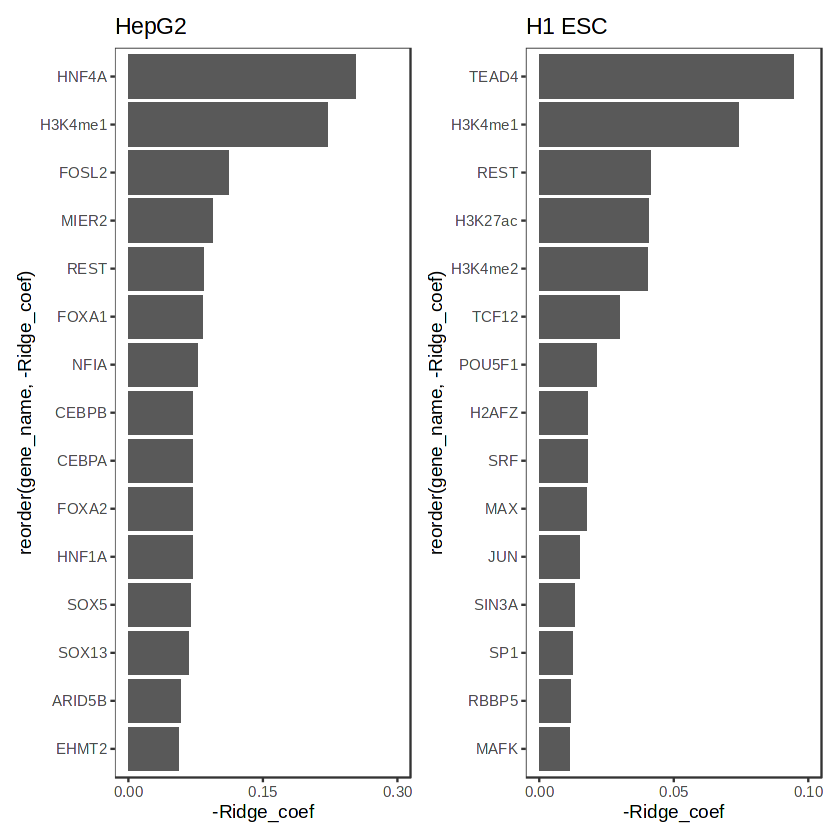

In [4]:
p1 | p2
ggsave("PanelK.pdf", height=2.5, width=5)